# Задание 3. Сегментация стран по структуре торговли с Республикой Беларусь

**Цель.** Выделить группы стран-партнёров со схожей товарной структурой экспорта и импорта Беларуси, описать профиль каждой группы и визуализировать разбиение.

**Входные данные.**

| Файл | Размер матрицы | Содержимое |
|---|---|---|
| `export_synth.xlsx` | 40 стран × 12 товарных групп | экспорт, 2021 г. |
| `import_synth.xlsx` | 36 стран × 12 товарных групп | импорт, 2021 г. |

В каждом файле три листа: «Стоимость, млн USD», «Доли, %» (матрица для кластеризации) и «Описание».

> **Ограничение данных.** Файлы синтетические

**Ход работы**

1. Загрузка и валидация данных
2. Формирование признаков
3. Выбор числа кластеров
4. Сравнение алгоритмов (K-means, Ward, DBSCAN)
5. Итоговые кластеры и их профили
6. Визуализация (PCA, t-SNE, тепловая карта)
7. Сопоставление экспорта и импорта
8. Выводы и ограничения

In [2]:
SEED = 42
SEARCH_DIRS = [Path("."), Path("/content"), Path("/kaggle/input")]

def find_file(keyword):
    for base in SEARCH_DIRS:
        if base.exists():
            hits = sorted(base.rglob(f"*{keyword}*.xlsx"))
            if hits:
                return hits[0]
    return None

KEYWORDS = {"Экспорт": "export_synth", "Импорт": "import_synth"}

if not all(find_file(k) for k in KEYWORDS.values()):
    try:
        from google.colab import files          # только в Google Colab
        print("Выберите оба файла: export_synth.xlsx и import_synth.xlsx")
        files.upload()
    except ImportError:
        pass

FILES = {flow: find_file(k) for flow, k in KEYWORDS.items()}
missing = [k for flow, k in KEYWORDS.items() if FILES[flow] is None]
if missing:
    raise FileNotFoundError(f"Не найдены файлы: {missing}. Положите их в папку с ноутбуком.")
print("Файлы:", {flow: str(p) for flow, p in FILES.items()})

Выберите оба файла: export_synth.xlsx и import_synth.xlsx


Saving export_synth.xlsx to export_synth.xlsx
Saving import_synth.xlsx to import_synth.xlsx
Файлы: {'Экспорт': 'export_synth.xlsx', 'Импорт': 'import_synth.xlsx'}


## Методология

**Признаки.** Строка матрицы — страна, столбец — доля товарной группы в обороте с этой страной (сумма по строке = 1). Масштабирование столбцов не применяется

Кластеризуются доли: на Россию приходится около половины оборота, и разбиение по объёмам определялось бы размером партнёра, а не структурой торговли. Объёмы (млн USD) используются только для описания готовых кластеров.

Евклидово расстояние по долям. Для проверки устойчивости результат сравнивается с разбиением по преобразованию Хеллингера (√доля), которое снижает вес крупных долей и корректно работает с нулями.

**Алгоритмы.**

- *K-means*
- *Ward (иерархический)*
- *DBSCAN*

**Выбор k.** Критерии: silhouette (выше лучше), Davies–Bouldin (ниже лучше), локоть по inertia и устойчивость — средний ARI между эталонным разбиением и разбиениями на случайных 80%-подвыборках (100 повторов). Значение k = 2 исключено как тривиальное: оно делит страны на два крупных блока и не даёт сегментации.

**Воспроизводимость.** `random_state = 42`, `n_init` от 50 до 100.

## 1. Загрузка и валидация

Проверки: пропуски, сумма долей по строке, согласованность листа «Доли» с пересчётом из «Стоимости», совпадение суммы групп с колонкой «Итого».

In [3]:
def load_flow(path):
    """Читает файл потока: стоимости, доли и список товарных групп."""
    val = pd.read_excel(path, sheet_name="Стоимость, млн USD").set_index("Страна")
    shr = pd.read_excel(path, sheet_name="Доли, %").set_index("Страна")
    groups = [c for c in shr.columns if c != "ISO3" and not c.startswith("Итого")]
    return dict(val=val, shr=shr, groups=groups)

data = {flow: load_flow(DATA_DIR / f) for flow, f in FILES.items()}

checks = []
for flow, d in data.items():
    s, v = d["shr"][d["groups"]], d["val"][d["groups"]]
    recomputed = v.div(v.sum(axis=1), axis=0) * 100
    checks.append({
        "поток": flow,
        "стран": len(s),
        "товарных групп": len(d["groups"]),
        "пропусков": int(s.isna().sum().sum()),
        "нулевых долей, %": round((s == 0).mean().mean() * 100, 1),
        "макс. |Σдолей − 100|, п.п.": round((s.sum(axis=1) - 100).abs().max(), 3),
        "макс. |доля − пересчёт из млн USD|, п.п.": round((s - recomputed).abs().max().max(), 3),
        "Σгрупп = Итого": bool(np.allclose(v.sum(axis=1), d["val"]["Итого, млн USD"], atol=0.05)),
    })
pd.DataFrame(checks).set_index("поток").T

поток,Экспорт,Импорт
стран,40,36
товарных групп,12,12
пропусков,0,0
"нулевых долей, %",7.7,16.7
"макс. |Σдолей − 100|, п.п.",0.01,0.02
"макс. |доля − пересчёт из млн USD|, п.п.",0.01,0.01
Σгрупп = Итого,True,True


**Результат.** Данные полные: пропусков нет, суммы долей равны 100 с точностью до округления (≤ 0,02 п.п.), доли совпадают с пересчётом из стоимостей (≤ 0,01 п.п.), сумма групп равна «Итого». Матрицы разрежены: нулевые доли составляют 7,7% ячеек в экспорте и 16,7% в импорте. Ноль означает отсутствие товарной группы в торговле со страной, поэтому нули не считаются пропусками и не импутируются.

### EDA2

Левые графики: простое среднее долей по странам и структура, взвешенная по обороту. Правые: распределение оборота по странам.

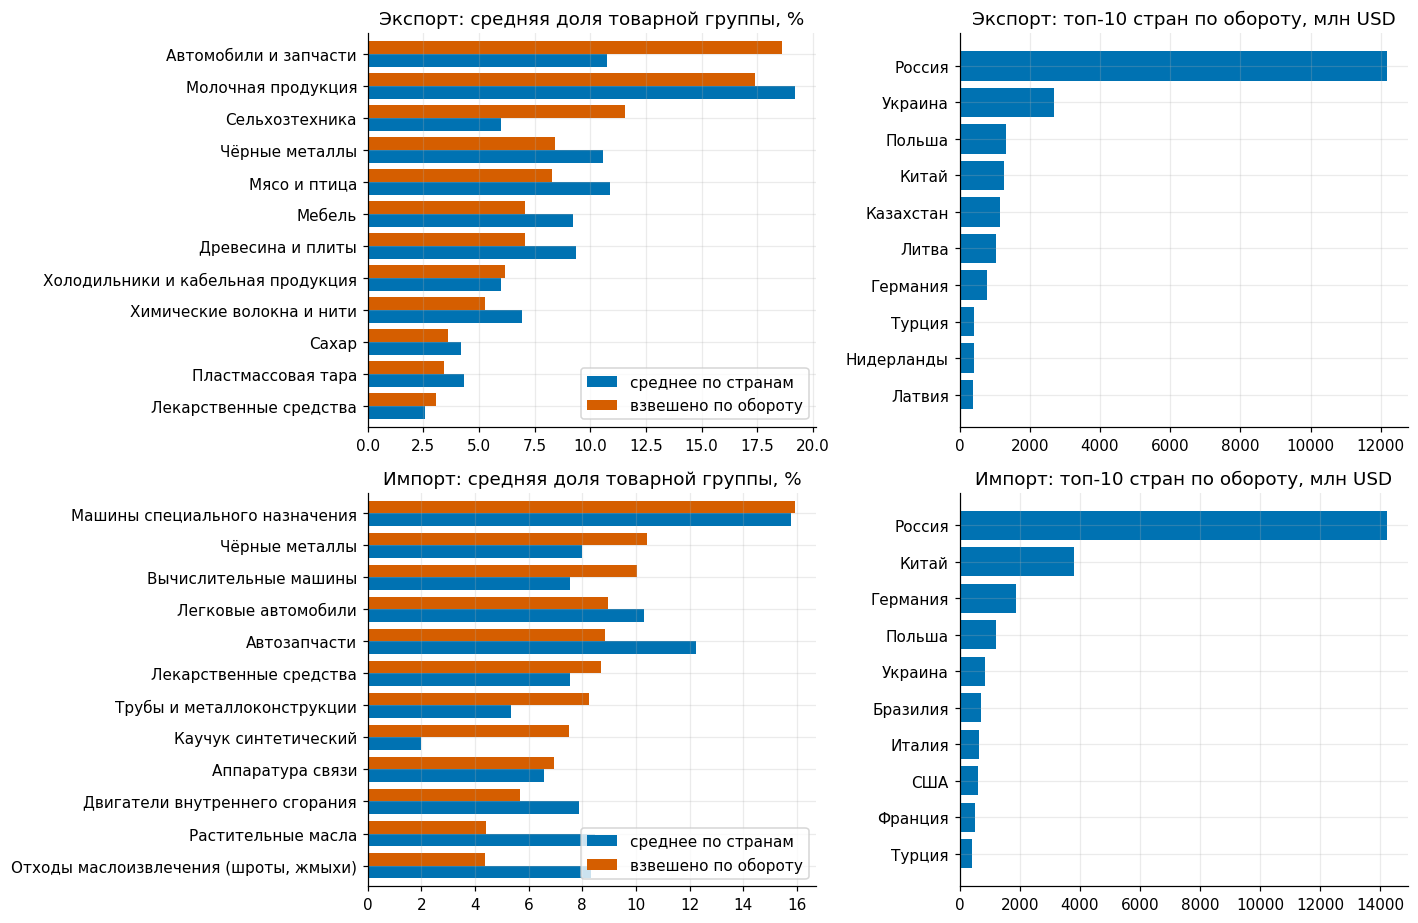

Экспорт: оборот 24,990 млн USD; топ-1 (Россия) = 48.7%; топ-5 = 74.3%; медиана по стране = 125 млн USD
Импорт: оборот 29,399 млн USD; топ-1 (Россия) = 48.3%; топ-5 = 74.6%; медиана по стране = 213 млн USD


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for row, (flow, d) in enumerate(data.items()):
    v, s, g = d["val"], d["shr"], d["groups"]
    total = v["Итого, млн USD"]

    # структура «средней страны» (простое среднее долей) и структура реального оборота (взвешенная)
    simple = s[g].mean()
    weighted = v[g].sum() / v[g].sum().sum() * 100
    cmp_ = pd.DataFrame({"среднее по странам": simple, "взвешено по обороту": weighted}).sort_values("взвешено по обороту")
    cmp_.plot.barh(ax=axes[row, 0], color=[PALETTE[0], PALETTE[1]], width=.8)
    axes[row, 0].set(title=f"{flow}: средняя доля товарной группы, %", ylabel="")

    top = total.sort_values(ascending=False).head(10)[::-1]
    axes[row, 1].barh(top.index, top.values, color=PALETTE[0])
    axes[row, 1].set(title=f"{flow}: топ-10 стран по обороту, млн USD")
plt.tight_layout()
plt.show()

for flow, d in data.items():
    t = d["val"]["Итого, млн USD"].sort_values(ascending=False)
    print(f"{flow}: оборот {t.sum():,.0f} млн USD; топ-1 ({t.index[0]}) = {t.iloc[0]/t.sum():.1%}; "
          f"топ-5 = {t.head(5).sum()/t.sum():.1%}; медиана по стране = {t.median():,.0f} млн USD")

**Результат.**

- Оборот сильно сконцентрирован: Россия даёт 48,7% экспорта и 48,3% импорта, пять крупнейших партнёров — около 74–75%. Медиана по стране — 125 млн USD в экспорте и 213 млн USD в импорте.
- Структура, взвешенная по обороту, заметно отличается от структуры «средней страны». В экспорте автомобили и запчасти весят около 19% против 11% в простом среднем, сельхозтехника — около 12% против 6%. В импорте синтетический каучук — около 7,5% против 2%, растительные масла — около 4,4% против 8,4%.
- Взвешенная структура фактически повторяет структуру торговли с Россией. Это подтверждает выбор: кластеризуем доли, где каждая страна имеет равный вес, а оборот используем только для интерпретации.

## 2. Формирование признаков

Матрица долей нормируется по строке к сумме 1, чтобы убрать дрейф округления (≤ 0,02 п.п.). Дополнительно строится вариант с преобразованием Хеллингера — он нужен только для проверки устойчивости.

In [ ]:
def make_matrix(d):
    """Матрица стран x групп с долями в [0, 1]; нормировка устраняет дрейф округления."""
    X = d["shr"][d["groups"]].to_numpy() / 100
    return X / X.sum(axis=1, keepdims=True)

for flow, d in data.items():
    d["X"] = make_matrix(d)
    d["X_hell"] = np.sqrt(d["X"])          # преобразование Хеллингера - для проверки устойчивости
    print(f"{flow}: матрица {d['X'].shape}, Σ по строкам: {d['X'].sum(axis=1).min():.3f}..{d['X'].sum(axis=1).max():.3f}")

Экспорт: матрица (40, 12), Σ по строкам: 1.000..1.000
Импорт: матрица (36, 12), Σ по строкам: 1.000..1.000


## 3. Выбор числа кластеров

K-means запускается для k = 2…8 на каждой матрице. Для каждого k считаются inertia, silhouette, Davies–Bouldin, Calinski–Harabasz и устойчивость на подвыборках.


Экспорт
   inertia  silhouette  davies_bouldin  calinski_harabasz  stability
k                                                                   
2     1.78        0.48            0.67              40.69       1.00
3     1.03        0.46            0.88              47.98       0.95
4     0.77        0.50            0.75              45.97       0.95
5     0.61        0.45            0.85              44.21       0.96
6     0.55        0.38            0.93              39.25       0.81
7     0.48        0.29            1.10              36.45       0.79
8     0.45        0.30            1.03              33.41       0.71

Импорт
   inertia  silhouette  davies_bouldin  calinski_harabasz  stability
k                                                                   
2     1.86        0.58            0.52              40.30       1.00
3     1.14        0.51            0.64              42.31       0.96
4     0.78        0.50            0.66              45.10       0.83
5     0.53       

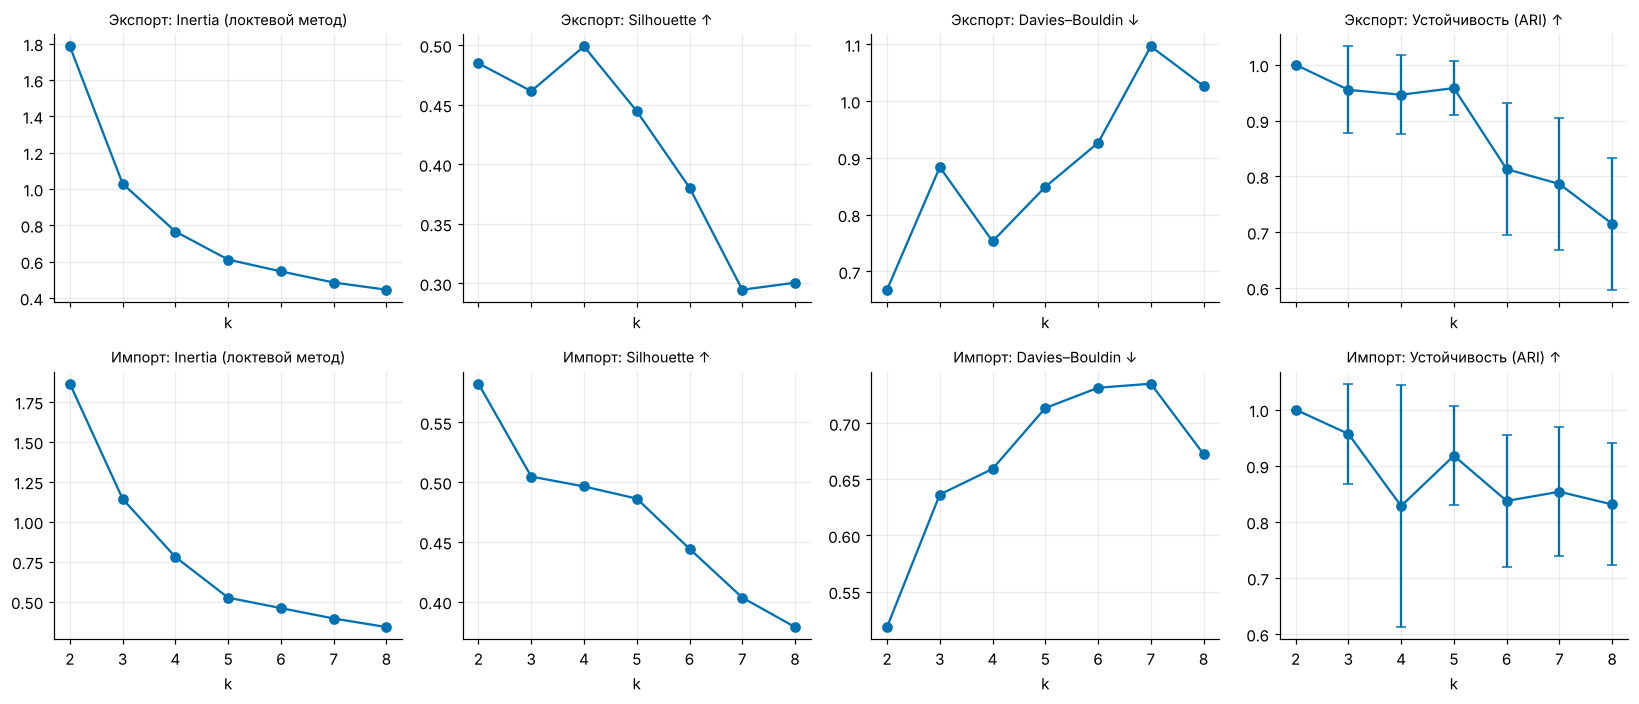

In [ ]:
KS = range(2, 9)

def scan_k(X, ks=KS):
    rows = []
    for k in ks:
        km = KMeans(k, n_init=50, random_state=SEED).fit(X)
        rows.append({"k": k, "inertia": km.inertia_,
                     "silhouette": silhouette_score(X, km.labels_),
                     "davies_bouldin": davies_bouldin_score(X, km.labels_),
                     "calinski_harabasz": calinski_harabasz_score(X, km.labels_)})
    return pd.DataFrame(rows).set_index("k")

def stability(X, k, n_rep=100, frac=.8):
    """Средний ARI между эталонным разбиением и разбиениями на случайных 80%-подвыборках."""
    rng = np.random.default_rng(SEED)
    ref = KMeans(k, n_init=50, random_state=SEED).fit_predict(X)
    scores = []
    for _ in range(n_rep):
        idx = rng.choice(len(X), int(frac * len(X)), replace=False)
        lab = KMeans(k, n_init=10, random_state=int(rng.integers(1_000_000))).fit_predict(X[idx])
        scores.append(adjusted_rand_score(ref[idx], lab))
    return np.mean(scores), np.std(scores)

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)
scans = {}
for row, (flow, d) in enumerate(data.items()):
    sc = scan_k(d["X"])
    sc["stability"], sc["stability_std"] = zip(*[stability(d["X"], k) for k in sc.index])
    scans[flow] = sc
    for ax, col, title in zip(axes[row], ["inertia", "silhouette", "davies_bouldin", "stability"],
                              ["Inertia (локтевой метод)", "Silhouette ↑", "Davies–Bouldin ↓", "Устойчивость (ARI) ↑"]):
        if col == "stability":
            ax.errorbar(sc.index, sc[col], yerr=sc["stability_std"], marker="o", color=PALETTE[0], capsize=3)
        else:
            ax.plot(sc.index, sc[col], marker="o", color=PALETTE[0])
        ax.set_title(f"{flow}: {title}", fontsize=9.5)
        ax.set_xlabel("k")
plt.tight_layout()
plt.show()

for flow, sc in scans.items():
    print(f"\n{flow}")
    print(sc[["inertia", "silhouette", "davies_bouldin", "calinski_harabasz", "stability"]].round(3).to_string())

**Результат.**

*Экспорт.* Silhouette максимален при k = 4 (0,50; при k = 3 — 0,46, при k = 5 — 0,45) и резко падает при k ≥ 6 (≤ 0,38). По Davies–Bouldin k = 4 (0,75) лучше k = 3 (0,88). Локоть inertia проходит в районе k = 3–4. Устойчивость ARI ≥ 0,95 для k ≤ 5 и падает до 0,81 при k = 6. **Выбрано k = 4.**

*Импорт.* Silhouette при k = 3, 4, 5 почти не различается (0,51 / 0,50 / 0,49), то есть метрики не определяют k однозначно. Устойчивость: 0,96 при k = 3, 0,83 при k = 4, 0,92 при k = 5. **Выбрано k = 4** по содержательным причинам:

- при k = 3 китайско-азиатская электроника (Китай, Вьетнам, Тайвань, Малайзия) не выделяется и входит в «основной» кластер из 25 стран;
- при k = 5 блок «машины и автомобили» делится на две подгруппы, различающиеся на 9–16 п.п. по двум-трём группам. Это вариация внутри одного профиля, а не новый профиль.

Цена выбора — устойчивость 0,83, минимальная среди рассмотренных k. Её источник — граничные страны (в первую очередь Россия, см. раздел 5).

Фиксируем число кластеров.

In [ ]:
K = {"Экспорт": 4, "Импорт": 4}      # число кластеров, обоснование - в тексте выше

## 4. Сравнение алгоритмов

Разбиение K-means сравнивается с Ward, с K-means на преобразовании Хеллингера и с DBSCAN. Мера согласия — скорректированный индекс Рэнда (ARI): 1 — полное совпадение, около 0 — случайное. Параметр `eps` для DBSCAN выбран по графику расстояния до 3-го соседа: значение 0,20 лежит перед резким ростом расстояний у последних 4–5 стран.

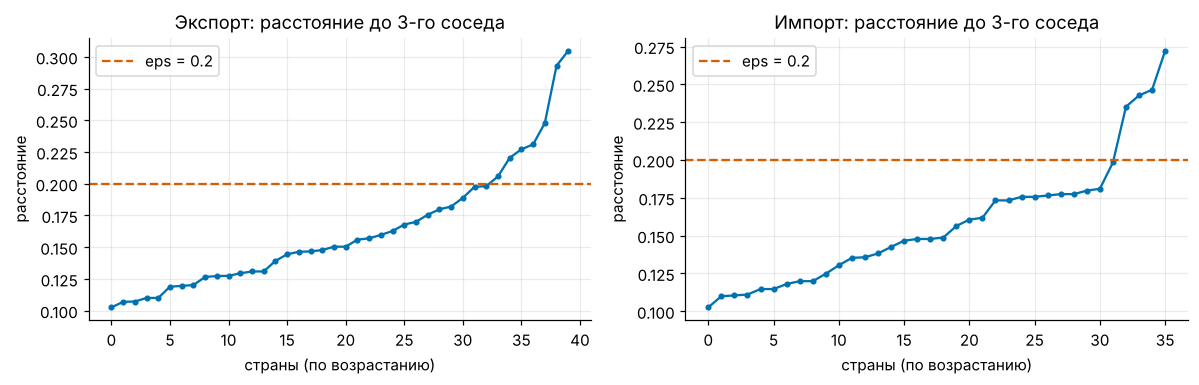

,k,ARI K-means vs Ward,ARI K-means vs K-means (Хеллингер),ARI K-means vs DBSCAN,DBSCAN: кластеров,DBSCAN: шум
поток,,,,,,
Экспорт,4,1.00,0.81,1.00,3,3
Импорт,4,0.91,1.00,0.98,4,1


In [ ]:
EPS, MIN_SAMPLES = 0.20, 3            # параметры DBSCAN (см. график k-distance)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (flow, d) in zip(axes, data.items()):
    kd = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES + 1).fit(d["X"]).kneighbors(d["X"])[0][:, -1])
    ax.plot(kd, marker=".", color=PALETTE[0]); ax.axhline(EPS, color=PALETTE[1], ls="--", label=f"eps = {EPS}")
    ax.set(title=f"{flow}: расстояние до {MIN_SAMPLES}-го соседа", xlabel="страны (по возрастанию)", ylabel="расстояние")
    ax.legend()
plt.tight_layout(); plt.show()

rows = []
for flow, d in data.items():
    k = K[flow]
    km = KMeans(k, n_init=100, random_state=SEED).fit_predict(d["X"])
    ward = AgglomerativeClustering(k, linkage="ward").fit_predict(d["X"])
    km_h = KMeans(k, n_init=100, random_state=SEED).fit_predict(d["X_hell"])
    db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(d["X"])
    rows.append({"поток": flow, "k": k,
                 "ARI K-means vs Ward": adjusted_rand_score(km, ward),
                 "ARI K-means vs K-means (Хеллингер)": adjusted_rand_score(km, km_h),
                 "ARI K-means vs DBSCAN": adjusted_rand_score(km, db),
                 "DBSCAN: кластеров": len(set(db) - {-1}), "DBSCAN: шум": int((db == -1).sum())})
pd.DataFrame(rows).set_index("поток").round(2)

**Результат.**

| Сравнение | Экспорт | Импорт |
|---|---|---|
| K-means vs Ward | 1,00 | 0,91 |
| K-means vs K-means (Хеллингер) | 0,81 | 1,00 |
| K-means vs DBSCAN | 1,00 | 0,98 |

- Разбиение воспроизводится тремя алгоритмами, то есть не является артефактом K-means.
- Экспорт, Хеллингер (ARI 0,81): «ядро» Э1 (Россия и страны СНГ) отделяется от «периферии» из Украины, США, Индии и Бразилии, которая объединяется с Турцией, Румынией и Венгрией. Остальные кластеры не меняются. Значит, граница Э1/Э4 нестрогая.
- DBSCAN в экспорте выдаёт 3 кластера и 3 шумовые точки — это Турция, Румыния и Венгрия (Э4). Формально ARI = 1,00, так как шум учитывается как отдельная метка. По существу DBSCAN считает группу из трёх стран слишком малой для кластера.
- DBSCAN в импорте выдаёт 4 кластера и 1 шумовую точку — Россию. Это согласуется с её низким силуэтом (раздел 5).

## 5. Итоговые кластеры и профили

Кластеры нумеруются по убыванию размера (префикс Э — экспорт, И — импорт). Для каждого считаются число стран, оборот и его доля, средний silhouette и три ведущие группы по центроиду.

In [ ]:
def fit_final(flow):
    d = data[flow]
    X, groups = d["X"], d["groups"]
    km = KMeans(K[flow], n_init=100, random_state=SEED).fit(X)

    # нумерация кластеров по убыванию размера, префикс Э/И
    order = np.argsort(-np.bincount(km.labels_))
    remap = {old: new for new, old in enumerate(order, 1)}
    prefix = "Э" if flow == "Экспорт" else "И"
    labels = np.array([f"{prefix}{remap[l]}" for l in km.labels_])
    centers = pd.DataFrame(km.cluster_centers_[order] * 100, columns=groups,
                           index=[f"{prefix}{i}" for i in range(1, K[flow] + 1)])

    res = d["shr"][["ISO3"]].copy()
    res["cluster"] = labels
    res["silhouette"] = silhouette_samples(X, labels)
    res["turnover"] = d["val"]["Итого, млн USD"]
    d.update(res=res, centers=centers, km=km)

for flow in data:
    fit_final(flow)

def cluster_profile(flow):
    d = data[flow]; res, centers = d["res"], d["centers"]
    rows = []
    for c in centers.index:
        members = res[res.cluster == c]
        top = centers.loc[c].sort_values(ascending=False).head(3)
        rows.append({"кластер": c, "стран": len(members),
                     "оборот, млн USD": members.turnover.sum(),
                     "доля оборота, %": members.turnover.sum() / res.turnover.sum() * 100,
                     "silhouette (ср.)": members.silhouette.mean(),
                     "ведущие группы, %": "; ".join(f"{g} {v:.0f}" for g, v in top.items()),
                     "страны": ", ".join(members.sort_values("turnover", ascending=False).index)})
    return pd.DataFrame(rows).set_index("кластер")

for flow in data:
    print(f"\n=== {flow} (k = {K[flow]}), silhouette всей выборки = {data[flow]['res'].silhouette.mean():.3f} ===")
    display(cluster_profile(flow).drop(columns="страны")
            .round({"оборот, млн USD": 0, "доля оборота, %": 1, "silhouette (ср.)": 2}))
    for c, g in data[flow]["res"].groupby("cluster"):
        print(f"{c}: {', '.join(g.sort_values('turnover', ascending=False).index)}")


=== Экспорт (k = 4), silhouette всей выборки = 0.499 ===
Э1: Россия, Украина, Казахстан, США, Узбекистан, Молдова, Азербайджан, Индия, Кыргызстан, Армения, Бразилия, Грузия, Таджикистан, Монголия, Туркмения
Э2: Польша, Литва, Германия, Нидерланды, Латвия, Великобритания, Чехия, Эстония, Италия, Бельгия, Дания, Франция
Э3: Китай, ОАЭ, Алжир, Саудовская Аравия, Египет, Сербия, Иран, Ирак, Вьетнам, Ливия
Э4: Турция, Румыния, Венгрия

=== Импорт (k = 4), silhouette всей выборки = 0.496 ===
И1: Германия, Польша, Италия, США, Франция, Турция, Республика Корея, Нидерланды, Литва, Индия, Япония, Чехия, Швейцария, Бельгия, Великобритания, Австрия, Словакия, Испания, Швеция, Таиланд
И2: Россия, Украина, Латвия, Болгария, Румыния, Финляндия
И3: Бразилия, Аргентина, Казахстан, Индонезия, Узбекистан, Парагвай
И4: Китай, Вьетнам, Тайвань, Малайзия


,стран,"оборот, млн USD","доля оборота, %",silhouette (ср.),"ведущие группы, %"
кластер,,,,,
Э1,15,17353.0,69.4,0.40,Автомобили и запчасти 19; Молочная продукция 16; Сельхозтехника 12
Э2,12,4964.0,19.9,0.50,Древесина и плиты 24; Химические волокна и нити 15; Мебель 15
Э3,10,2076.0,8.3,0.67,Молочная продукция 47; Мясо и птица 29; Сахар 3
Э4,3,597.0,2.4,0.44,Чёрные металлы 37; Молочная продукция 11; Холодильники и кабельная продукция 7


,стран,"оборот, млн USD","доля оборота, %",silhouette (ср.),"ведущие группы, %"
кластер,,,,,
И1,20,8310.0,28.3,0.40,Машины специального назначения 22; Автозапчасти 17; Легковые автомобили 16
И2,6,15429.0,52.5,0.48,Чёрные металлы 32; Трубы и металлоконструкции 18; Машины специального назначения 11
И3,6,1482.0,5.0,0.75,"Отходы маслоизвлечения (шроты, жмыхи) 47; Растительные масла 40; Автозапчасти 3"
И4,4,4177.0,14.2,0.62,Аппаратура связи 29; Вычислительные машины 21; Машины специального назначения 14


**Профили кластеров.**

*Экспорт* (silhouette всей выборки 0,50)

| Кластер | Стран | Доля оборота | Профиль |
|---|---|---|---|
| Э1 | 15 | 69,4% | Диверсифицированный машинно-продовольственный: автомобили и запчасти 19%, молочная продукция 16%, сельхозтехника 12%, мебель 10%. Россия, Украина, Казахстан, США, Индия, страны СНГ. Ни одна группа не превышает 20%, поэтому кластер самый «размытый» (silhouette 0,4) |
| Э2 | 12 | 19,9% | ЕС и Великобритания. Древесина и плиты 24%, химические волокна 15%, мебель 15%, чёрные металлы 13%: сырьевой и полуфабрикатный профиль |
| Э3 | 10 | 8,3% | Китай, Вьетнам, Ближний Восток и Северная Африка, Сербия. Молочная продукция 47% и мясо 29% — 76% оборота приходится на продовольствие. Самый компактный кластер экспорта (silhouette 0,67) |
| Э4 | 3 | 2,4% | Турция, Румыния, Венгрия. Чёрные металлы 37% (в 3,5 раза выше среднего), молочная продукция 11% |

*Импорт* (silhouette всей выборки 0,50)

| Кластер | Стран | Доля оборота | Профиль |
|---|---|---|---|
| И1 | 20 | 28,3% | Западная и восточноазиатская «машиностроительная» группа: Германия, Польша, Италия, США, Франция, Турция, Корея, Япония, Индия и др. Машины спец. назначения 22%, автозапчасти 17%, легковые автомобили 16%. Lift ≤ 1,5, то есть профиль выражен слабо |
| И2 | 6 | 52,5% | Россия, Украина, Латвия, Болгария, Румыния, Финляндия. Чёрные металлы 32% (×4,0 к среднему), трубы и металлоконструкции 18% (×3,4). Без России доля оборота кластера — 4,2% |
| И3 | 6 | 5,0% | Бразилия, Аргентина, Парагвай, Индонезия, Казахстан, Узбекистан. Шроты и жмыхи 47% (×5,6) и растительные масла 40% (×4,8) — 87% оборота. Самый чёткий профиль (silhouette 0,75) |
| И4 | 4 | 14,2% | Китай, Вьетнам, Тайвань, Малайзия. Аппаратура связи 29% (×4,4), вычислительные машины 21% (×2,8), машины спец. назначения 14% |

**Граничные страны** (silhouette < 0,25): Индия в экспорте (0,03; ближайший чужой кластер Э2), Украина в экспорте (0,20) и **Россия в импорте (0,02; ближайший чужой кластер И1)**. Россия — крупнейший партнёр, и её отнесение к И2 на 52,5% определяет оборот кластера. Выводы об «обороте кластера И2» поэтому чувствительны к одной точке; по структуре Россия — смесь металлов и машин, не вписывающаяся целиком ни в И1, ни в И2.

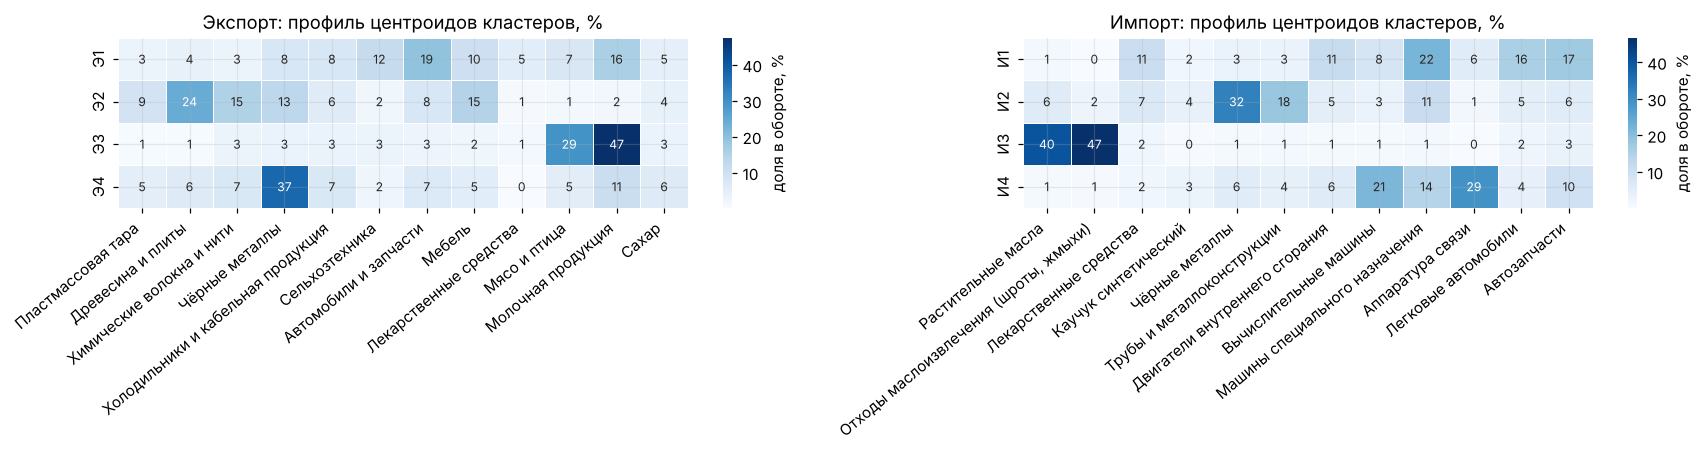

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1, 1]})
for ax, (flow, d) in zip(axes, data.items()):
    sns.heatmap(d["centers"], annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "доля в обороте, %"},
                linewidths=.5, ax=ax, annot_kws={"size": 8})
    ax.set(title=f"{flow}: профиль центроидов кластеров, %", xlabel="", ylabel="")
    ax.tick_params(axis="x", rotation=40)
    plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout(); plt.show()

In [ ]:
# Специализация: во сколько раз доля группы в кластере выше средней по выборке (lift)
for flow, d in data.items():
    base = d["X"].mean(axis=0) * 100
    lift = d["centers"].div(base.reshape(1, -1))
    top = {c: ", ".join(f"{g} (x{lift.loc[c, g]:.1f})" for g in lift.loc[c].sort_values(ascending=False).head(3).index)
           for c in lift.index}
    print(f"\n{flow}: группы с максимальным lift")
    for c, t in top.items():
        print(f"  {c}: {t}")


Экспорт: группы с максимальным lift
  Э1: Лекарственные средства (x2.1), Сельхозтехника (x2.0), Автомобили и запчасти (x1.8)
  Э2: Древесина и плиты (x2.6), Химические волокна и нити (x2.2), Пластмассовая тара (x2.0)
  Э3: Мясо и птица (x2.7), Молочная продукция (x2.5), Сахар (x0.8)
  Э4: Чёрные металлы (x3.5), Сахар (x1.5), Холодильники и кабельная продукция (x1.2)

Импорт: группы с максимальным lift
  И1: Легковые автомобили (x1.5), Двигатели внутреннего сгорания (x1.4), Автозапчасти (x1.4)
  И2: Чёрные металлы (x4.0), Трубы и металлоконструкции (x3.4), Каучук синтетический (x1.9)
  И3: Отходы маслоизвлечения (шроты, жмыхи) (x5.6), Растительные масла (x4.8), Автозапчасти (x0.3)
  И4: Аппаратура связи (x4.4), Вычислительные машины (x2.8), Каучук синтетический (x1.4)


In [ ]:
# Страны с низким силуэтом: лежат на границе кластеров. Для них указан ближайший «чужой» кластер.
for flow, d in data.items():
    res, centers, X = d["res"], d["centers"], d["X"]
    dist = pd.DataFrame(np.linalg.norm(X[:, None, :] - centers.to_numpy()[None] / 100, axis=2),
                        index=res.index, columns=centers.index)
    own = res.cluster
    other = dist.apply(lambda r: r.drop(own[r.name]).idxmin(), axis=1)
    weak = res.assign(ближайший_чужой=other)[res.silhouette < 0.25].sort_values("silhouette")
    print(f"\n{flow}: страны с silhouette < 0.25 ({len(weak)} из {len(res)})")
    display(weak[["cluster", "ближайший_чужой", "silhouette", "turnover"]].round(2))


Экспорт: страны с silhouette < 0.25 (2 из 40)

Импорт: страны с silhouette < 0.25 (1 из 36)


,cluster,ближайший_чужой,silhouette,turnover
Страна,,,,
Индия,Э1,Э2,0.03,129.35
Украина,Э1,Э3,0.20,2695.95


,cluster,ближайший_чужой,silhouette,turnover
Страна,,,,
Россия,И2,И1,0.02,14205.99


## 6. Визуализация

Три представления:

1. **PCA** — линейная проекция на 2 главные компоненты; оси интерпретируемы через нагрузки, расстояния сохраняются.
2. **t-SNE** (perplexity = 8, при n ≈ 40 большие значения не имеют смысла) — нелинейная проекция, лучше разделяет локальные группы. Расстояния между кластерами на ней интерпретировать нельзя.
3. **Тепловая карта** исходных долей по странам, упорядоченным по кластерам — показывает данные без проекции.

Экспорт: объяснённая дисперсия первых 4 компонент = [0.624 0.175 0.082 0.031]
  PC1: Молочная продукция (+0.75), Мясо и птица (+0.44), Древесина и плиты (-0.33)
  PC2: Автомобили и запчасти (+0.61), Древесина и плиты (-0.49), Сельхозтехника (+0.44)


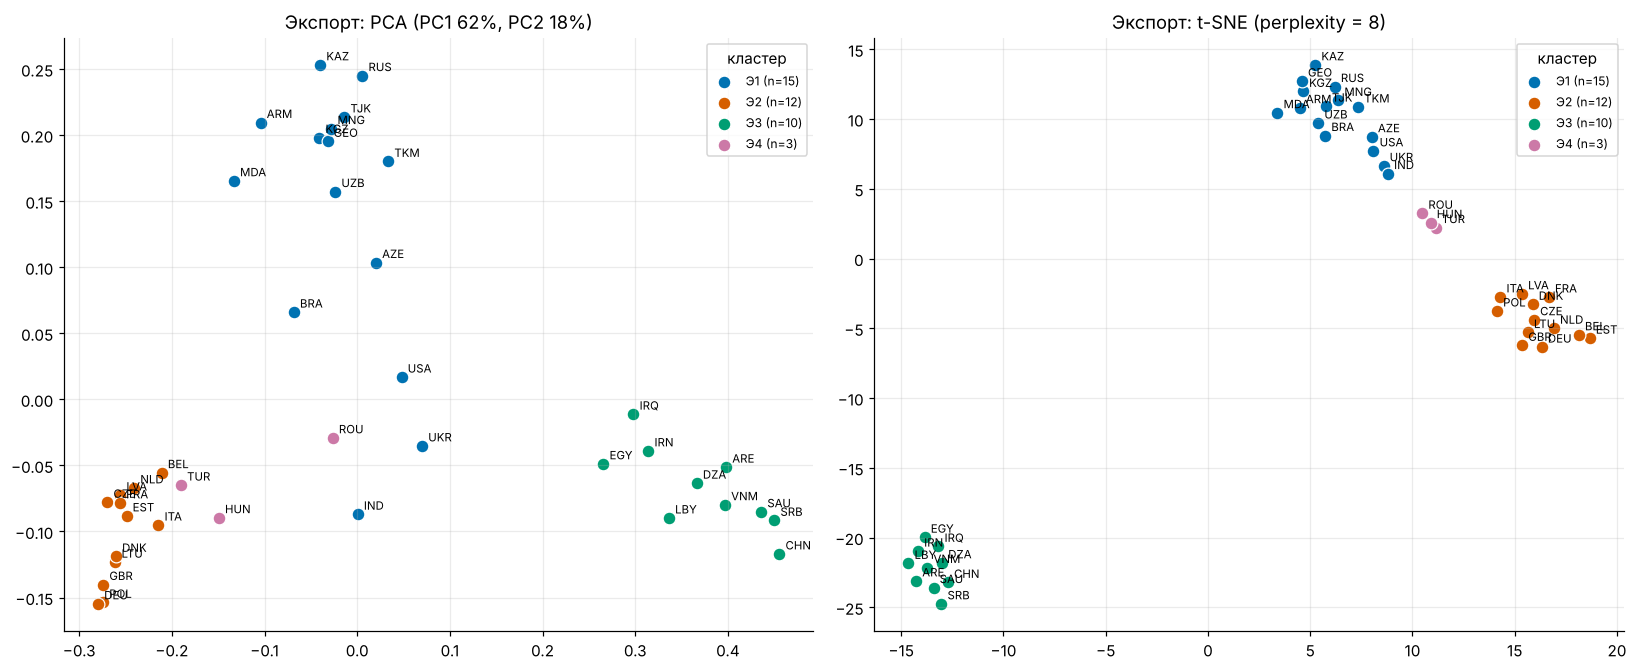

In [ ]:
def plot_embedding(flow):
    d = data[flow]; X, res = d["X"], d["res"]
    pca = PCA(n_components=2, random_state=SEED).fit(X)
    Z_pca = pca.transform(X)
    Z_tsne = TSNE(n_components=2, perplexity=8, init="pca", random_state=SEED).fit_transform(X)
    colors = {c: PALETTE[i] for i, c in enumerate(d["centers"].index)}

    fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
    for ax, Z, title in zip(axes, [Z_pca, Z_tsne],
                            [f"PCA (PC1 {pca.explained_variance_ratio_[0]:.0%}, PC2 {pca.explained_variance_ratio_[1]:.0%})",
                             "t-SNE (perplexity = 8)"]):
        for c in d["centers"].index:
            m = (res.cluster == c).to_numpy()
            ax.scatter(Z[m, 0], Z[m, 1], s=70, color=colors[c], label=f"{c} (n={m.sum()})", edgecolor="white", lw=.8)
        for (x, y), iso in zip(Z, res.ISO3):
            ax.annotate(iso, (x, y), xytext=(4, 3), textcoords="offset points", fontsize=7.5)
        ax.set_title(f"{flow}: {title}")
        ax.legend(title="кластер", loc="best", fontsize=8)
    plt.tight_layout(); plt.show()

    load = pd.DataFrame(pca.components_.T, index=d["groups"], columns=["PC1", "PC2"])
    print(f"{flow}: объяснённая дисперсия первых 4 компонент = "
          f"{PCA(4).fit(X).explained_variance_ratio_.round(3)}")
    for pc in ["PC1", "PC2"]:
        top = load[pc].reindex(load[pc].abs().sort_values(ascending=False).index).head(3)
        print(f"  {pc}: " + ", ".join(f"{g} ({v:+.2f})" for g, v in top.items()))

plot_embedding("Экспорт")

**Результат (экспорт).** Первые две компоненты объясняют 80% дисперсии (62% + 18%). PC1 противопоставляет молочную продукцию и мясо древесине (нагрузки +0,75, +0,44 и −0,33), отделяя Э3 (справа) от Э2 (слева). PC2 определяется автомобилями, сельхозтехникой и древесиной (+0,61, +0,44, −0,49) и разводит Э1 (вверху) и Э2. Э4 лежит между Э1 и Э2, что согласуется с нестрогой границей из раздела 4. На t-SNE все четыре кластера разделены.

Импорт: объяснённая дисперсия первых 4 компонент = [0.556 0.186 0.105 0.072]
  PC1: Отходы маслоизвлечения (шроты, жмыхи) (+0.68), Растительные масла (+0.57), Машины специального назначения (-0.29)
  PC2: Чёрные металлы (+0.78), Трубы и металлоконструкции (+0.41), Автозапчасти (-0.27)


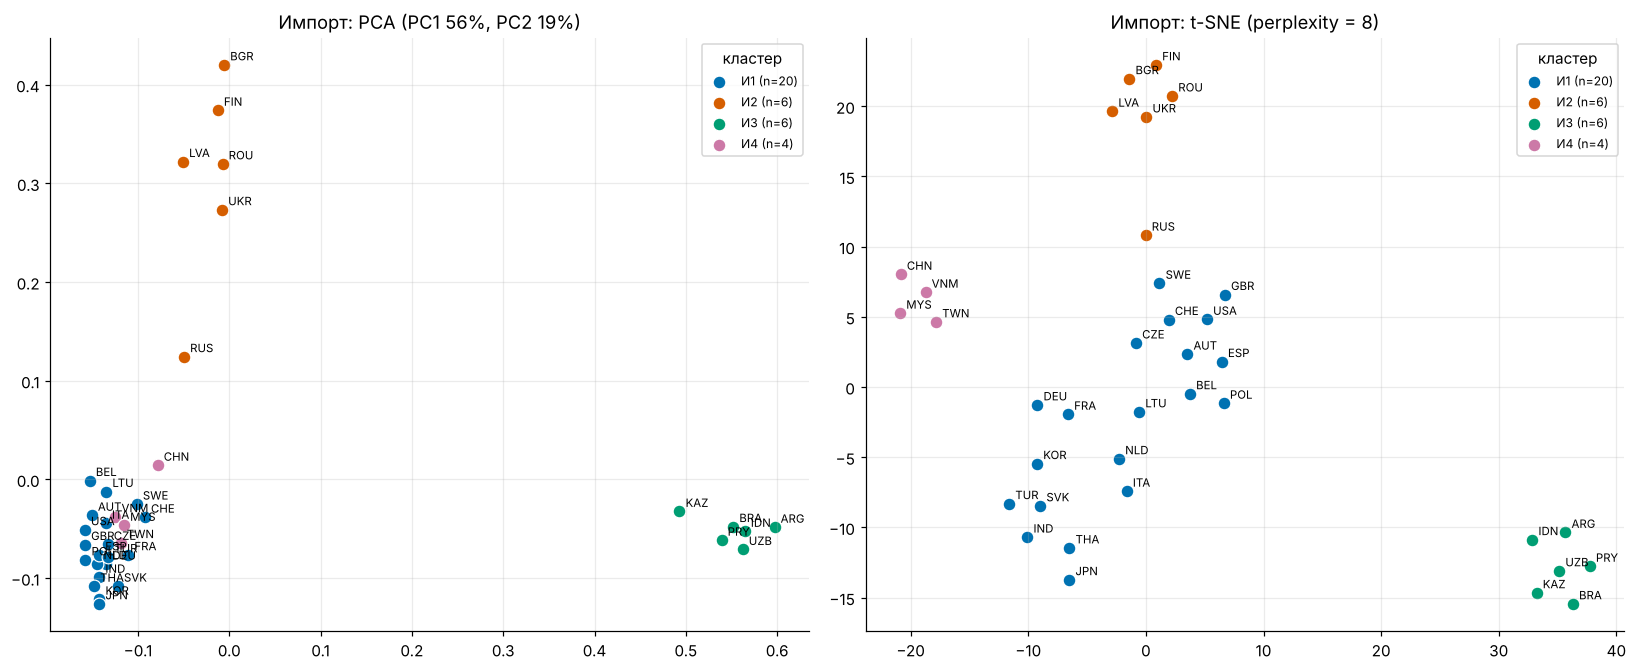

In [ ]:
plot_embedding("Импорт")

**Результат (импорт).** Две компоненты объясняют 74% дисперсии (56% + 19%). PC1 — шроты и растительные масла против машин (+0,68, +0,57, −0,29) — отделяет И3. PC2 — чёрные металлы (+0,78) — отделяет И2. Кластеры И1 и И4 на плоскости PC1–PC2 перекрываются: электроника проявляется в более слабых компонентах. t-SNE их разделяет, при этом внутри И1 заметен градиент (Япония, Таиланд, Индия, Корея — в нижней части), согласующийся с долей автозапчастей и легковых автомобилей. Россия на обеих проекциях лежит между И1 и остальной частью И2.

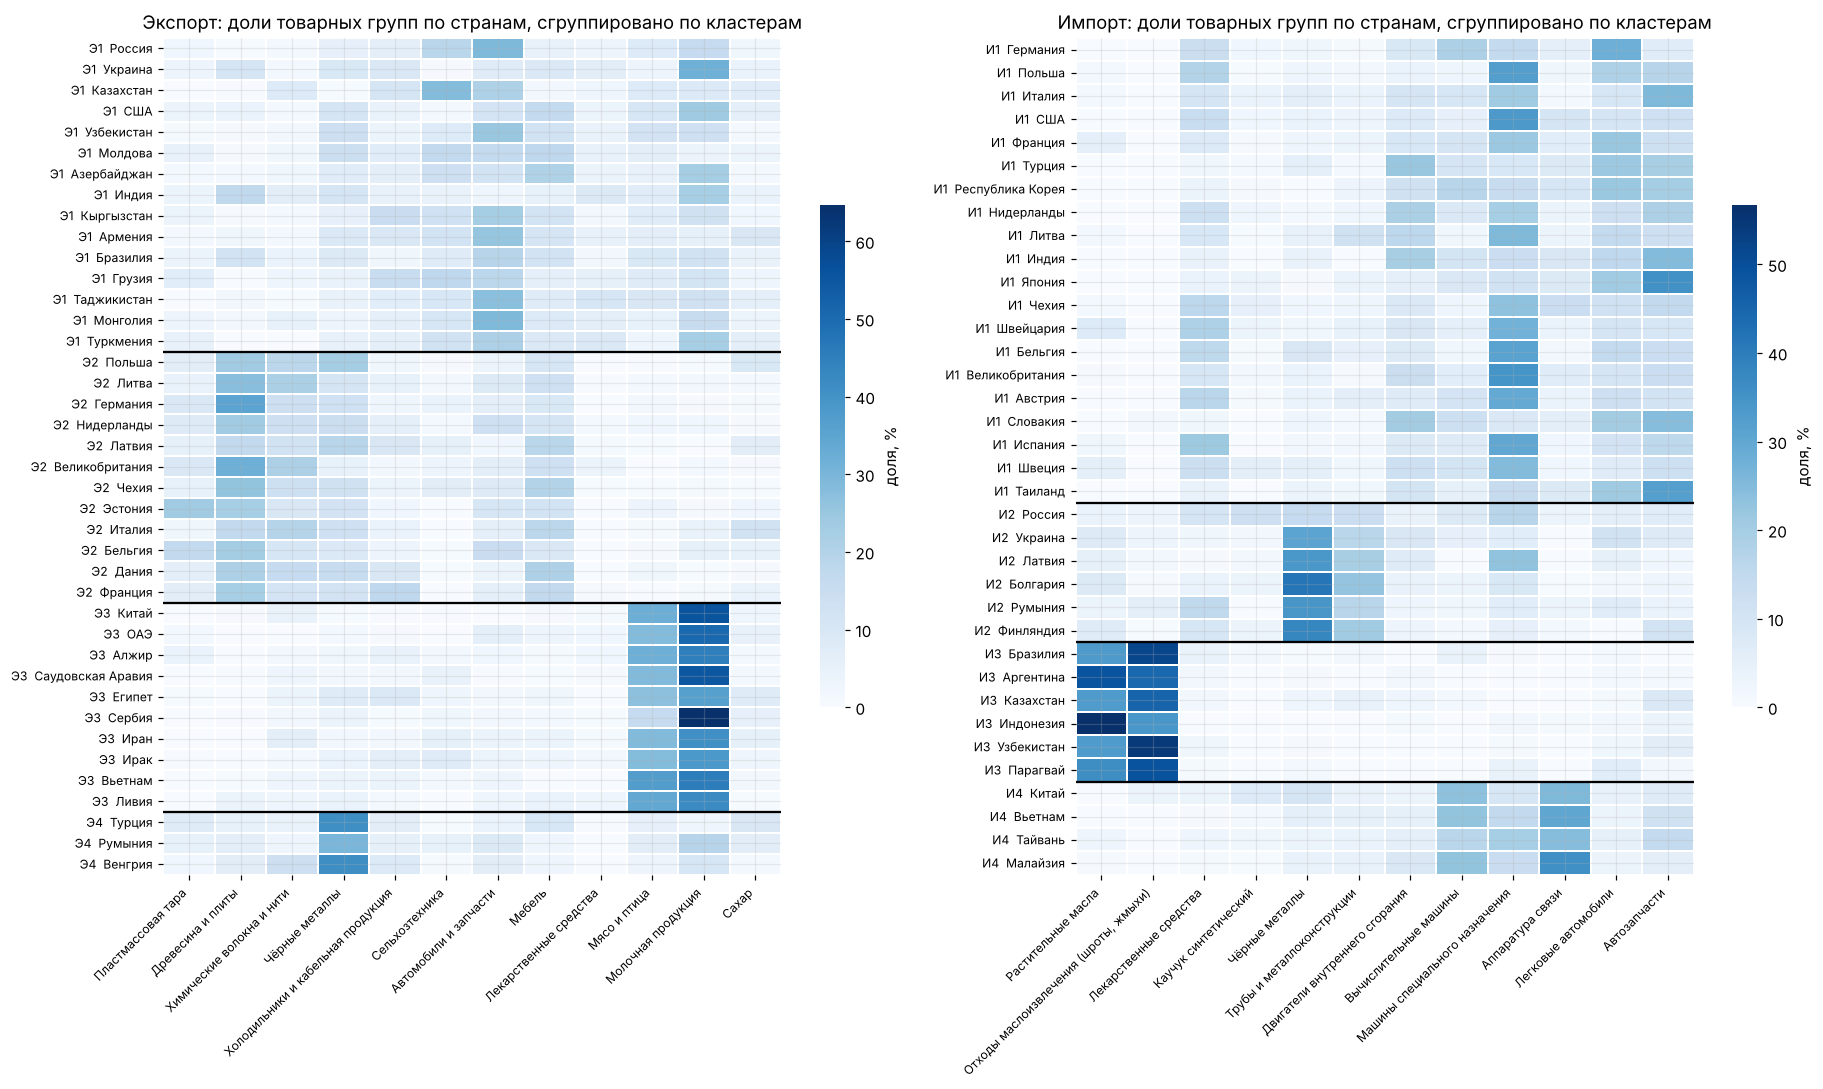

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(17, 10))
for ax, (flow, d) in zip(axes, data.items()):
    res = d["res"].sort_values(["cluster", "turnover"], ascending=[True, False])
    M = d["shr"].loc[res.index, d["groups"]]
    sns.heatmap(M, cmap="Blues", vmin=0, ax=ax, linewidths=.3, linecolor="white",
                cbar_kws={"label": "доля, %", "shrink": .6})
    # границы кластеров и подписи
    bounds = np.cumsum(res.groupby("cluster", sort=True).size().to_numpy())
    for b in bounds[:-1]:
        ax.axhline(b, color="black", lw=1.5)
    ax.set_yticklabels([f"{c}  {n}" for n, c in zip(res.index, res.cluster)], fontsize=8)
    ax.set(title=f"{flow}: доли товарных групп по странам, сгруппировано по кластерам", xlabel="", ylabel="")
    ax.tick_params(axis="x", rotation=45); plt.setp(ax.get_xticklabels(), ha="right", fontsize=8)
plt.tight_layout(); plt.show()

**Результат.** Кластеры с выраженной специализацией (Э3, Э4, И2, И3, И4) видны как сплошные блоки в одних и тех же столбцах. Строки Э1 и И1 заполнены равномернее: их профиль задаётся сочетанием нескольких групп, а не одной.

## 7. Сопоставление экспорта и импорта

Для стран, присутствующих в обеих выборках (сопоставление по ISO3), строится таблица сопряжённости кластеров экспорта и импорта.

In [ ]:
# Страны, присутствующие и в экспортной, и в импортной выборке
e, i = data["Экспорт"]["res"].reset_index(), data["Импорт"]["res"].reset_index()
both = e.merge(i, on="ISO3", suffixes=("_эксп", "_имп"))
print(f"Общих стран: {len(both)}")
display(pd.crosstab(both["cluster_эксп"], both["cluster_имп"], margins=True))
both[["Страна_эксп", "ISO3", "cluster_эксп", "cluster_имп"]].rename(columns={"Страна_эксп": "Страна"}).set_index("Страна").T

Общих стран: 21


cluster_имп,И1,И2,И3,И4,All
cluster_эксп,,,,,
Э1,2,2,3,0,7
Э2,9,1,0,0,10
Э3,0,0,0,2,2
Э4,1,1,0,0,2
All,12,4,3,2,21


Страна,Россия,Казахстан,Узбекистан,Польша,Литва,Латвия,Германия,Нидерланды,Чехия,Италия,Франция,Бельгия,Великобритания,Китай,Вьетнам,Украина,Турция,США,Индия,Бразилия,Румыния
ISO3,RUS,KAZ,UZB,POL,LTU,LVA,DEU,NLD,CZE,ITA,FRA,BEL,GBR,CHN,VNM,UKR,TUR,USA,IND,BRA,ROU
cluster_эксп,Э1,Э1,Э1,Э2,Э2,Э2,Э2,Э2,Э2,Э2,Э2,Э2,Э2,Э3,Э3,Э1,Э4,Э1,Э1,Э1,Э4
cluster_имп,И2,И3,И3,И1,И1,И2,И1,И1,И1,И1,И1,И1,И1,И4,И4,И2,И1,И1,И1,И3,И2


**Результат.** Общих стран — 21.

- **ЕС и Великобритания** (Э2): 9 из 10 общих стран попадают в И1. Беларусь поставляет им древесину, химию и мебель, а закупает у них машины и автомобильные компоненты.
- **Китай и Вьетнам**: оба — в Э3 по экспорту (продовольствие) и в И4 по импорту (электроника).
- **Бразилия, Казахстан, Узбекистан**: в импорте — И3 (масличное сырьё), в экспорте — Э1.
- **Россия и Украина**: Э1 по экспорту, И2 по импорту.

Страны почти не сохраняют кластер при переходе от экспорта к импорту: структура торговли в двух направлениях асимметрична. В синтетических данных это следствие способа генерации профилей, на реальных данных эту гипотезу нужно проверять.

Сохраняем результат для дальнейшего использования (например, для карты - гео не строил)

In [ ]:
for flow, d in data.items():
    out = d["res"].reset_index().rename(columns={"cluster": "кластер", "turnover": "оборот_млн_USD"})
    fname = f"clusters_{'export' if flow == 'Экспорт' else 'import'}.csv"
    out.round(3).to_csv(fname, index=False, encoding="utf-8-sig")
    print("сохранено:", fname)

сохранено: clusters_export.csv
сохранено: clusters_import.csv


## 8. Выводы

**Данные.** Экспорт: 40 стран, 24 990 млн USD; импорт: 36 стран, 29 399 млн USD; по 12 товарных групп. Пропусков нет, расхождение долей с пересчётом из стоимостей ≤ 0,01 п.п. Нулевые доли: 7,7% ячеек (экспорт), 16,7% (импорт). Оборот сконцентрирован: Россия — 48,7% экспорта и 48,3% импорта, топ-5 партнёров — 74,3% и 74,6%. Структура, взвешенная по обороту, повторяет структуру торговли с Россией, поэтому кластеризация выполнена по долям групп (равный вес стран)

**Выбор k.**

| | Silhouette k = 3 / 4 / 5 | Устойчивость ARI k = 3 / 4 / 5 | Выбрано |
|---|---|---|---|
| Экспорт | 0,46 / **0,50** / 0,45 | 0,95 / 0,95 / 0,96 | k = 4 (максимум silhouette при k ≥ 3; DB 0,75 против 0,88 при k = 3) |
| Импорт | 0,51 / 0,50 / 0,49 | 0,96 / 0,83 / 0,92 | k = 4 (метрики различаются на ≤ 0,02, выбор по интерпретируемости) |

**Сравнение алгоритмов (ARI относительно K-means).** Ward: 1,00 (экспорт) и 0,91 (импорт). K-means на √долях: 0,81 и 1,00. DBSCAN (eps = 0,20, min_samples = 3): 1,00 и 0,98. Расхождение 0,81 в экспорте — перенос Украины, США, Индии и Бразилии из Э1 в кластер с Турцией, Румынией и Венгрией.

**Кластеры.**

| Кластер | Стран | Оборот, млн USD | Доля оборота | Silhouette | Профиль (доля, lift) |
|---|---|---|---|---|---|
| Э1 | 15 | 17 353 | 69,4% | 0,40 | автомобили 19%, молочная продукция 16%, сельхозтехника 12%; максимум по группе < 20% |
| Э2 | 12 | 4 964 | 19,9% | 0,50 | древесина 24% (×2,6), хим. волокна 15% (×2,2), мебель 15% |
| Э3 | 10 | 2 076 | 8,3% | 0,67 | молочная продукция 47% + мясо 29% = 76% |
| Э4 | 3 | 597 | 2,4% | 0,44 | чёрные металлы 37% (×3,5) |
| И1 | 20 | 8 310 | 28,3% | 0,40 | машины спец. назначения 22%, автозапчасти 17%, легковые 16%; lift ≤ 1,5 |
| И2 | 6 | 15 429 | 52,5% | 0,48 | чёрные металлы 32% (×4,0), трубы 18% (×3,4) |
| И3 | 6 | 1 482 | 5,0% | 0,75 | шроты 47% (×5,6) + растительные масла 40% (×4,8) = 87% |
| И4 | 4 | 4 177 | 14,2% | 0,62 | аппаратура связи 29% (×4,4), вычислительные машины 21% (×2,8) |

Средний silhouette: 0,499 (экспорт), 0,496 (импорт). Специализированные кластеры (Э3, И3, И4) компактнее диверсифицированных (Э1, И1: 0,40).

**Граничные страны (silhouette < 0,25).** Индия (экспорт) — 0,03, Украина (экспорт) — 0,20, Россия (импорт) — 0,02. Россия даёт 14 206 из 15 429 млн USD оборота И2; без неё доля И2 падает с 52,5% до 4,2%. Показатели оборота по И2 определяются одной точкой.

**Визуализация.** Две главные компоненты объясняют 80% дисперсии в экспорте (62% + 18%) и 74% в импорте (56% + 19%); четыре компоненты — 91% и 92%. В экспорте PCA разделяет все четыре кластера. В импорте И1 и И4 на плоскости PC1–PC2 перекрываются, их разделяет t-SNE.

**Экспорт и импорт.** Из 21 общей страны 9 из 10 стран Э2 (ЕС и Великобритания) попадают в И1; Китай и Вьетнам относятся к Э3 по экспорту и к И4 по импорту. Структуры двух направлений не совпадают, но в синтетических данных это следствие генерации.

**Ограничения.**

- *Синтетические данные.* Профили заданы генератором (seed 2021); выводы не переносятся на реальную торговлю.
- *Объём выборки.* n = 36–40. Кластеры из 3–4 стран (Э4, И4) меняются при удалении одной страны; устойчивость импорта при k = 4 — 0,83.
- *Жёсткое разбиение.* Россия (импорт), Индия, Украина (экспорт) имеют смешанный профиль; для них применимы GMM или нечёткая кластеризация.
- *Только доли.* Страны с оборотом 50 млн USD и 12 млрд USD при схожей структуре попадают в один кластер.
- *Форма кластеров.* K-means предполагает компактные кластеры сопоставимого размера; проверка DBSCAN показала один шумовой объект в импорте (Россия) и три в экспорте (Э4).